# 4장 2강 · 이미지 군집화와 결과 해석

실습문제

사진 자료실에 들어온 반려동물 사진을 묶어 검토하려고 합니다. 대표 사진 한 장으로 폴더를 설명해도 될까요? 기존 폴더와 잘 어울리지 않는 새 사진은 어떤 순서로 열어 봐야 할까요? 실제 사진의 거리와 품종 분포를 근거로 답해 봅시다.

## 실습 목표와 데이터

| 구간 | 판단할 내용 | 제출할 근거 |
|---|---|---|
| 필수 1 | K-Means가 사진을 어느 중심에 배정했는가? | 파일별 소속, 직접 계산한 거리와 중심, 거리 제곱합 |
| 필수 2 | 묶음을 설명하는 사진과 사람이 더 살펴볼 사진은 각각 무엇인가? | 대표·구성 사진, 두 중심까지의 거리 차이, K=2와 K=3의 대응표 |
| 과제 1 | 사진이 늘어나면 어떤 수의 폴더를 만들고 무엇부터 검토할까? | K 후보별 지표, 5개 폴더의 구성, 새 사진 검토 목록 |

**준비물**  강의용 `oxford_dataset.zip`을 압축 상태로 노트북과 같은 폴더에 둡니다. 다른 위치라면 첫 코드 셀의 `paths`를 수정하세요. ZIP 안의 `val.csv`, `test.csv`와 거기에 기록된 이미지 경로를 읽습니다. Python 3, Jupyter, PyTorch, torchvision, scikit-learn, NumPy, pandas, Pillow를 사용합니다. 검증한 모델 환경은 CPU용 PyTorch 2.6.0, torchvision 0.21.0, scikit-learn 1.8.0입니다. ResNet18 가중치는 처음 사용할 때 다운로드하며 이후에는 로컬 캐시를 사용합니다.

**실행 순서**  공통 준비 두 셀을 실행한 뒤 각 구간 안에서는 번호순으로 진행하세요. 필수 2와 과제 1은 공통 준비 직후에도 시작할 수 있습니다. 품종명은 표본을 고르고 결과를 해석할 때 사용합니다. 군집 모델에 넣는 입력은 사진에서 얻은 숫자뿐입니다.

### 공통 준비 ① · 같은 사진을 두 번 세지 않도록 나누기

| 용도 | 사진 수 | 선택 방법 |
|---|---:|---|
| 기본 실습 | 12 | 기존 실습의 비글·퍼그·페르시안 각 4장. 파일명을 고정합니다. |
| 확장 실험의 군집 학습 | 120 | 비글·퍼그·복서·페르시안·버만 각 24장. 이 사진으로 중심을 구합니다. |
| 확장 실험의 새 사진 | 40 | 위 다섯 품종 각 8장. 중심을 정한 뒤 처음 배정합니다. |

기본 사진은 배포본의 val 목록에서 읽습니다. 확장 실험은 test 목록에서 품종별 32장을 중복 없이 뽑아 24장과 8장으로 나눕니다. 여기서 ‘학습’과 ‘새 사진’은 이번 군집 실험 안에서의 역할입니다. `sort_index()`로 후보 순서를 고정하고 난수 시드 42를 사용합니다. 이미지 ID 간 중복도 검사합니다.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display
import torch
from torch import nn
from torchvision.models import ResNet18_Weights, resnet18
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

paths = [Path("oxford_dataset.zip")]
data_path = next((p for p in paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("강의용 Oxford ZIP을 노트북 옆에 두거나 paths를 수정하세요.")

demo_ids = ["beagle_110", "beagle_111", "beagle_117", "beagle_126",
            "pug_100", "pug_103", "pug_105", "pug_116",
            "Persian_100", "Persian_125", "Persian_135", "Persian_138"]
breeds = ["beagle", "pug", "boxer", "Persian", "Birman"]
fit_ids, new_ids = [], []
rng = np.random.default_rng(42)
with ZipFile(data_path) as archive:
    val = pd.read_csv(archive.open("val.csv")).set_index("image_id")
    test = pd.read_csv(archive.open("test.csv")).set_index("image_id")
    available = test.loc[test.image_path.isin(archive.namelist())].sort_index()
    for breed in breeds:
        pool = available.index[available.class_name == breed]
        chosen = rng.choice(pool, 32, replace=False).tolist()
        fit_ids.extend(chosen[:24])
        new_ids.extend(chosen[24:])
    all_ids = demo_ids + fit_ids + new_ids
    assert len(set(all_ids)) == len(all_ids)
    meta = pd.concat([val.loc[demo_ids], test.loc[fit_ids + new_ids]])
    photos = {}
    for key in all_ids:
        with Image.open(BytesIO(archive.read(meta.at[key,"image_path"]))) as im:
            photos[key] = im.convert("RGB")
print("기본 / 확장 학습 / 새 사진", len(demo_ids), len(fit_ids), len(new_ids))

def photo_grid(keys):
    cols = min(4, len(keys))
    sheet = Image.new("RGB", (cols*162, ((len(keys)+cols-1)//cols)*145), "white")
    draw = ImageDraw.Draw(sheet)
    for i,key in enumerate(keys):
        im = ImageOps.contain(photos[key], (158,117))
        x, y = (i%cols)*162, (i//cols)*145
        sheet.paste(im, (x+(158-im.width)//2,y))
        draw.text((x+3,y+120),key,fill="black")
    return sheet

기본 / 확장 학습 / 새 사진 12 120 40


### 공통 준비 ② · 사진을 같은 좌표계의 특징으로 나타내기

원본을 RGB로 통일하고 사전학습 가중치의 전처리를 적용합니다. 짧은 변을 256으로 조정하고 가운데 224×224를 자른 다음, 픽셀을 텐서로 바꾸고 채널별로 표준화합니다. `eval()`은 모델을 평가 모드로 돌리고 `inference_mode()`는 추론 중 기울기 기록을 생략합니다. 마지막 분류층을 `Identity()`로 바꾸면 사진별 512개 특징이 그대로 나옵니다. 여기서 ResNet18은 특징 추출기로 사용하고, K-Means는 다음 문항에서 사진으로 새로 학습합니다.

`torch.stack`은 여러 사진 앞에 배치 축을 추가합니다. 최대 16장씩 처리해 메모리 사용량을 줄입니다. `features`의 행 이름은 파일 ID입니다. `matrix(keys)`는 지정한 ID 순서대로 숫자 행만 가져옵니다. 모든 실험은 이렇게 얻은 원래 임베딩의 유클리드 거리를 사용합니다.

In [2]:
torch.set_num_threads(2)
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
encoder = resnet18(weights=weights)
encoder.fc = nn.Identity()
encoder.eval()
parts = []
with torch.inference_mode():
    for start in range(0, len(all_ids), 16):
        keys = all_ids[start:start+16]
        batch = torch.stack([preprocess(photos[key]) for key in keys])
        parts.append(encoder(batch).numpy())
features = pd.DataFrame(np.concatenate(parts), index=all_ids)
def matrix(keys):
    return features.loc[keys].to_numpy(dtype=np.float64)
X_demo, X_fit, X_new = [matrix(keys) for keys in (demo_ids,fit_ids,new_ids)]
print("임베딩 전체 / 기본 / 확장 학습 / 새 사진",features.shape,X_demo.shape,X_fit.shape,X_new.shape)

def fit_kmeans(X, k):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    with threadpool_limits(limits=1):
        model.fit(X)
    return model

임베딩 전체 / 기본 / 확장 학습 / 새 사진 (172, 512) (12, 512) (120, 512) (40, 512)


## 필수 1 · 사진 12장을 두 군집으로 묶기

군집 모델이 실제로 받은 입력부터 확인합니다. 사진 한 장을 골라 거리, 소속, 중심 갱신을 손으로 따라간 다음 12장 전체에서 검산하세요.

### 1-1. 사진 ID와 임베딩 한 행을 연결하기

기본 표본의 첫 사진에 대해 원본 크기, 전처리 텐서의 모양, 임베딩 앞 다섯 값을 출력하세요. ID로 다시 꺼낸 행과 첫 행이 같은지, 기본 표본에 결측·무한값이 없는지도 확인하세요. 품종 분류와 이번 군집화에 쓰이는 정보의 차이를 적으세요.

**풀이 단서**  
Pillow의 size는 가로부터, PyTorch 이미지 텐서는 채널부터 읽습니다. np.array_equal은 두 배열을 원소별로 비교합니다.

In [3]:
# 1-1 실습 코드
key = demo_ids[0]
tensor = preprocess(photos[key])
first_row = X_demo[0]
by_id = matrix([key])[0]
print("첫 사진 ID:", key, "/ 품종:", meta.at[key, "class_name"])
print("원본 크기 (가로, 세로):", photos[key].size)
print("전처리 텐서 모양 (채널, 세로, 가로):", tuple(tensor.shape))
print("임베딩 길이:", first_row.shape[0])
print("임베딩 앞 다섯 값:", np.round(first_row[:5], 4))
print("ID로 꺼낸 행 == X_demo 첫 행:", np.array_equal(by_id, first_row))
print("기본 표본 결측값 수:", int(np.isnan(X_demo).sum()), "/ 무한값 수:", int(np.isinf(X_demo).sum()))
print("모든 값이 유한한가:", bool(np.isfinite(X_demo).all()))

첫 사진 ID: beagle_110 / 품종: beagle
원본 크기 (가로, 세로): (437, 500)
전처리 텐서 모양 (채널, 세로, 가로): (3, 224, 224)
임베딩 길이: 512
임베딩 앞 다섯 값: [0.5961 1.7446 0.6655 1.0984 3.358 ]
ID로 꺼낸 행 == X_demo 첫 행: True
기본 표본 결측값 수: 0 / 무한값 수: 0
모든 값이 유한한가: True


**나의 답안**

- **근거:**
  - 첫 사진 `beagle_110`의 원본 크기는 Pillow 기준 **(가로 437, 세로 500)** 이고, 전처리 후 텐서는 채널부터 읽어 **(3, 224, 224)** 입니다.
  - 임베딩은 **512개** 값이며 앞 다섯 값은 **[0.5961, 1.7446, 0.6655, 1.0984, 3.358]** 입니다.
  - `matrix(["beagle_110"])`로 다시 꺼낸 행과 `X_demo` 첫 행은 `np.array_equal` 결과 **True** 로 같고, 기본 표본 12장의 결측값 **0개**, 무한값 **0개** 입니다.
- **판단:** 원본 크기가 달라도 전처리가 모든 사진을 같은 3×224×224 입력으로 맞추고, ResNet18이 사진 한 장을 512차원 좌표 한 행으로 바꿉니다. ID로 꺼낸 행이 첫 행과 같으므로 이후 표의 행 번호를 파일 ID로 안전하게 되짚을 수 있고, 결측·무한값이 없어 거리 계산에 문제가 없습니다. 품종 분류는 사람이 붙인 정답 품종(`class_name`)을 학습해 이름을 예측하지만, 이번 군집화는 이 512개 숫자 사이의 유클리드 거리만 입력으로 받고 품종명은 전혀 보지 않습니다. 따라서 군집 번호는 "어떤 품종인가"가 아니라 "특징 공간에서 서로 가까운 사진끼리"라는 뜻이며, 품종명은 학습이 끝난 뒤 해석할 때만 사용합니다.

### 1-2. K=2를 학습하고 모든 사진에 소속 붙이기

기본 표본에 K=2, random_state=42, n_init=10으로 K-Means를 학습하세요. 파일별 군집 번호와 군집별 사진 수, 선택된 실행의 반복 횟수를 확인하고 n_init과 반복 횟수의 차이를 설명하세요.

**풀이 단서**  
공통 함수 fit_kmeans(X, k)는 .fit()까지 끝난 모델을 반환합니다. labels_의 n번째 원소를 n번째 사진에 붙이세요.

In [4]:
# 1-2 실습 코드
model2 = fit_kmeans(X_demo, 2)
base = pd.DataFrame({"cluster": model2.labels_}, index=pd.Index(demo_ids, name="image_id"))
display(base)
print("군집별 사진 수:", np.bincount(model2.labels_).tolist())
print("n_init(서로 다른 초기 중심으로 반복한 실행 수):", model2.n_init)
print("선택된 실행의 반복 횟수 n_iter_:", model2.n_iter_)
print("선택된 실행의 inertia_:", round(model2.inertia_, 2))

,cluster
image_id,
beagle_110,0
beagle_111,0
beagle_117,0
beagle_126,0
pug_100,0
pug_103,0
pug_105,0
pug_116,0
Persian_100,1


군집별 사진 수: [8, 4]
n_init(서로 다른 초기 중심으로 반복한 실행 수): 10
선택된 실행의 반복 횟수 n_iter_: 2
선택된 실행의 inertia_: 2355.96


**나의 답안**

- **근거:**
  - K=2 결과 `beagle_110·111·117·126`, `pug_100·103·105·116` 8장이 **군집 0**, `Persian_100·125·135·138` 4장이 **군집 1** 로, 군집별 사진 수는 **[8, 4]** 입니다.
  - `n_init`은 **10**, 선택된 실행의 반복 횟수 `n_iter_`는 **2**, 그 실행의 `inertia_`는 **2355.96** 입니다.
- **판단:** `n_init=10`은 서로 다른 초기 중심으로 K-Means를 **처음부터 10번 따로 실행**한다는 뜻이고, 그중 거리 제곱합(inertia)이 가장 작은 실행 하나를 최종 모델로 고릅니다. `n_iter_=2`는 그렇게 선택된 **한 번의 실행 안에서** "가까운 중심에 배정 → 중심을 평균으로 갱신"을 2번 반복한 뒤 수렴했다는 뜻입니다. 즉 n_init은 초기값 운에 대비한 재시작 횟수, n_iter_는 한 실행의 수렴 속도이며, 반복이 2번으로 끝난 것은 개·고양이 사진이 특징 공간에서 이미 뚜렷하게 떨어져 있어 배정이 금방 안정되었다는 근거입니다.

### 1-3. 한 사진의 거리와 한 중심의 평균을 직접 검산하기

첫 사진에서 두 중심까지의 거리를 NumPy로 직접 구하세요. 최소 거리의 번호와 모델 소속을 비교한 뒤 12장 전체에서도 같은지 검사하세요. 첫 사진이 속한 군집의 평균 벡터를 직접 구해 모델 중심과 대조하세요.

**풀이 단서**  
사진에서 중심을 빼면 (2, 512)입니다. sum(axis=1)은 각 중심의 512개 차이를 더하고, mean(axis=0)은 소속 사진들을 모아 특징별 평균을 냅니다.

In [5]:
# 1-3 실습 코드
dist2 = model2.transform(X_demo)
centers = model2.cluster_centers_
diff = X_demo[0] - centers                     # (2, 512)
manual = np.sqrt((diff ** 2).sum(axis=1))
print("첫 사진:", demo_ids[0])
print("직접 계산한 두 중심까지 거리:", np.round(manual, 4))
print("model2.transform 거리      :", np.round(dist2[0], 4))
print("최소 거리 중심 번호:", int(manual.argmin()), "/ 모델 소속:", int(model2.labels_[0]))

all_manual = np.sqrt(((X_demo[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2))
print("12장 거리표 일치(allclose):", np.allclose(all_manual, dist2))
print("12장 최소 거리 번호 == labels_:", np.array_equal(all_manual.argmin(axis=1), model2.labels_))

c0 = model2.labels_[0]
members = X_demo[model2.labels_ == c0]
mean_vec = members.mean(axis=0)
print(f"첫 사진의 군집 {c0} 사진 수:", len(members))
print("직접 구한 평균 앞 다섯 값:", np.round(mean_vec[:5], 4))
print("모델 중심 앞 다섯 값     :", np.round(centers[c0][:5], 4))
print("평균과 중심의 최대 절대 차이:", float(np.abs(mean_vec - centers[c0]).max()))
print("평균 == 중심 (allclose):", np.allclose(mean_vec, centers[c0]))

첫 사진: beagle_110
직접 계산한 두 중심까지 거리: [15.9622 31.2346]
model2.transform 거리      : [15.9622 31.2346]
최소 거리 중심 번호: 0 / 모델 소속: 0
12장 거리표 일치(allclose): True
12장 최소 거리 번호 == labels_: True
첫 사진의 군집 0 사진 수: 8
직접 구한 평균 앞 다섯 값: [0.6372 0.8328 1.4802 0.6468 1.4279]
모델 중심 앞 다섯 값     : [0.6372 0.8328 1.4802 0.6468 1.4279]
평균과 중심의 최대 절대 차이: 2.220446049250313e-16
평균 == 중심 (allclose): True


**나의 답안**

- **근거:**
  - `beagle_110`에서 두 중심까지 NumPy로 직접 구한 거리는 **[15.9622, 31.2346]** 으로 `model2.transform` 값과 같고, 최소 거리 번호 **0** 이 모델 소속 **0** 과 일치합니다.
  - 12장 전체에서도 직접 계산한 거리표가 `transform`과 같고(allclose **True**), 최소 거리 번호가 `labels_`와 모두 같습니다(**True**).
  - 군집 0의 8장을 평균한 벡터 앞 다섯 값 **[0.6372, 0.8328, 1.4802, 0.6468, 1.4279]** 가 모델 중심과 같고, 512개 특징 중 최대 절대 차이는 **2.2e-16** (부동소수점 오차 수준)입니다.
- **판단:** K-Means의 소속은 "512차원 공간에서 가장 가까운 중심"이라는 규칙 하나로 정해지며, 중심은 그 군집에 속한 사진 특징의 단순 평균입니다. 직접 계산과 모델 값이 모두 일치하므로 모델이 내부적으로 다른 정보를 쓰지 않았음을 확인했습니다. `beagle_110`은 군집 0 중심보다 군집 1 중심에서 약 2배(31.23 대 15.96) 멀어 배정이 분명한 사진입니다.

### 1-4. 거리 제곱합과 품종 교차표는 무엇을 재는가?

각 사진에서 자기 중심까지의 거리를 제곱해 모두 더하고 모델의 inertia_와 비교하세요. 학습을 마친 다음 ID로 품종을 붙여 군집×품종 교차표를 만드세요. 두 결과가 각각 답하는 질문을 쓰세요.

**풀이 단서**  
거리표에 min(axis=1)을 적용하면 사진별 최솟값이 남습니다. crosstab의 한 칸은 행과 열의 조건을 동시에 만족한 사진 수입니다.

In [6]:
# 1-4 실습 코드
own_dist = dist2.min(axis=1)
sse = float((own_dist ** 2).sum())
print("직접 계산한 거리 제곱합:", round(sse, 4))
print("model2.inertia_       :", round(float(model2.inertia_), 4))
print("일치 여부:", np.isclose(sse, model2.inertia_))

base["breed"] = meta.loc[base.index, "class_name"].values
cross = pd.crosstab(base["cluster"], base["breed"])
display(cross)

직접 계산한 거리 제곱합: 2355.9552
model2.inertia_       : 2355.9552
일치 여부: True


breed,Persian,beagle,pug
cluster,,,
0,0,4,4
1,4,0,0


**나의 답안**

- **근거:**
  - 사진별 자기 중심 거리(`min(axis=1)`)를 제곱해 더한 값 **2355.9552** 가 `model2.inertia_` **2355.9552** 와 일치합니다.
  - 군집×품종 교차표: 군집 0 = **beagle 4, pug 4**, 군집 1 = **Persian 4** 입니다.
- **판단:** 거리 제곱합은 "각 사진이 자기 중심 주위에 얼마나 촘촘히 모였는가"라는 **군집 내부의 응집도**를 재는 값으로, 품종 정보 없이 계산되고 K를 늘리면 거의 항상 줄어듭니다. 교차표는 학습이 끝난 뒤 품종명을 붙여 "**만들어진 묶음이 사람이 아는 범주와 어떻게 대응하는가**"를 묻는 외부 점검입니다. 이번 결과에서 K=2는 고양이(Persian)와 개(beagle+pug)를 완벽하게 나눴지만 개 두 품종은 한 묶음에 섞였으므로, inertia가 작다는 사실만으로 "품종별 폴더"라고 부를 수는 없습니다.

## 필수 2 · 대표 사진과 추가 검토 사진 고르기

각 군집의 표지 사진 한 장을 고른 다음, 그 표지가 놓치는 사진을 찾아보세요. 같은 사진 12장으로 K를 바꿔 어떤 묶음이 나뉘는지도 추적합니다.

### 2-1. 군집 중심과 가장 가까운 실제 사진 고르기

기본 12장에 K=2를 학습하고 각 사진의 소속 중심까지 거리를 구하세요. 군집마다 대표 한 장을 뽑아 ID·군집·거리와 두 사진을 제시하세요. 중심과 대표 사진이 어떻게 다른지 설명하세요.

**풀이 단서**  
각 군집 안에서 distance가 가장 작은 행을 고릅니다. 거리 동점일 때는 image_id 오름차순을 사용하세요.

,image_id,cluster,distance,breed
0,beagle_111,0,12.083,beagle
8,Persian_125,1,9.878,Persian


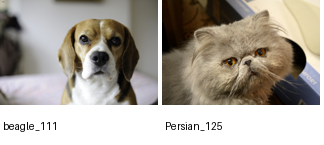

군집별 중심 거리 범위:


,min,mean,max
cluster,,,
0,12.083,14.974,20.710
1,9.878,11.248,12.758


군집 0 중심 L2 노름: 22.371, 대표 beagle_111 임베딩 L2 노름: 21.410
군집 1 중심 L2 노름: 30.903, 대표 Persian_125 임베딩 L2 노름: 31.016


In [7]:
# 2-1 실습 코드
m = fit_kmeans(X_demo, 2)
d = m.transform(X_demo)
ranked = pd.DataFrame({"image_id": demo_ids,
                       "cluster": m.labels_,
                       "distance": d[np.arange(len(demo_ids)), m.labels_]})
ranked["breed"] = meta.loc[ranked.image_id, "class_name"].values
ranked = ranked.sort_values(["cluster", "distance", "image_id"]).reset_index(drop=True)
reps = ranked.groupby("cluster").head(1)
display(reps.round(3))
display(photo_grid(reps.image_id.tolist()))
print("군집별 중심 거리 범위:")
display(ranked.groupby("cluster")["distance"].agg(["min", "mean", "max"]).round(3))
for cid in reps.cluster:
    rep_id = reps.loc[reps.cluster == cid, "image_id"].item()
    print(f"군집 {cid} 중심 L2 노름: {np.linalg.norm(m.cluster_centers_[cid]):.3f}, "
          f"대표 {rep_id} 임베딩 L2 노름: {np.linalg.norm(features.loc[rep_id]):.3f}")

**나의 답안**

- **근거:**
  - 군집 0 대표는 **`beagle_111`** (중심 거리 **12.083**), 군집 1 대표는 **`Persian_125`** (거리 **9.878**) 입니다.
  - 군집 0의 중심 거리는 최소 12.083 · 평균 14.974 · 최대 20.710, 군집 1은 9.878 · 11.248 · 12.758 입니다.
  - 군집 0 중심의 L2 노름은 **22.371**, 대표 `beagle_111` 임베딩은 **21.410**, 군집 1 중심은 **30.903**, `Persian_125`는 **31.016** 입니다.
- **판단:** 중심은 소속 사진 특징의 평균일 뿐 실제로 존재하는 사진이 아니어서 화면에 보여 줄 수 없습니다. 그래서 중심에 가장 가까운 **실제 사진**을 대표로 고릅니다. 다만 대표도 중심과 0이 아닌 거리(12.083, 9.878)만큼 떨어져 있습니다. 특히 군집 0의 중심은 비글 4장과 퍼그 4장을 섞은 평균이어서, 대표로 뽑힌 비글 한 장은 그 안의 퍼그 4장을 전혀 보여 주지 못합니다. 대표 사진은 "이 군집에서 가장 평균적인 한 장"이지 군집 구성 전체의 요약이 아닙니다.

### 2-2. 대표와 다른 구성 사진 찾기

두 군집의 전체 사진을 거리 오름차순으로 표시하세요. 각 군집에서 대표와 나머지 사진의 공통점 및 차이점을 하나씩 찾아 파일 ID와 함께 기록하세요. 화면에서 관찰한 사실과 모델 판단 원인에 대한 추측을 구분하세요.

**풀이 단서**  
groupby 후 기존 거리순을 유지하세요. 첫 사진이 대표이고 마지막은 그 군집 중심에서 가장 먼 사진입니다.

군집 0: 8장 (첫 사진이 대표, 마지막이 중심에서 가장 먼 사진)


,image_id,cluster,distance,breed
0,beagle_111,0,12.083,beagle
1,pug_100,0,12.837,pug
2,pug_103,0,12.941,pug
3,beagle_117,0,14.596,beagle
4,beagle_126,0,15.193,beagle
5,pug_105,0,15.467,pug
6,beagle_110,0,15.962,beagle
7,pug_116,0,20.710,pug


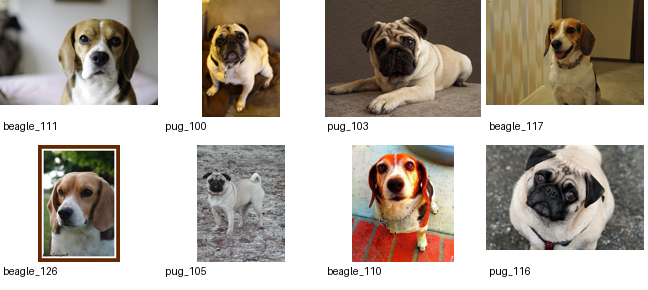

군집 1: 4장 (첫 사진이 대표, 마지막이 중심에서 가장 먼 사진)


,image_id,cluster,distance,breed
8,Persian_125,1,9.878,Persian
9,Persian_135,1,10.618,Persian
10,Persian_138,1,11.739,Persian
11,Persian_100,1,12.758,Persian


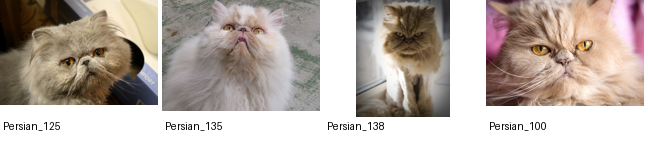

In [8]:
# 2-2 실습 코드
for cid, group in ranked.groupby("cluster"):
    print(f"군집 {cid}: {len(group)}장 (첫 사진이 대표, 마지막이 중심에서 가장 먼 사진)")
    display(group.round(3))
    display(photo_grid(group.image_id.tolist()))

**나의 답안**

- **근거:**
  - 군집 0(거리순): `beagle_111` 12.083 → `pug_100` 12.837 → `pug_103` 12.941 → `beagle_117` 14.596 → `beagle_126` 15.193 → `pug_105` 15.467 → `beagle_110` 15.962 → **`pug_116` 20.710** (가장 먼 사진).
  - 군집 1(거리순): `Persian_125` 9.878 → `Persian_135` 10.618 → `Persian_138` 11.739 → **`Persian_100` 12.758**.
  - **관찰 사실 (화면):**
    - 군집 0 공통점: 대표 `beagle_111`과 나머지 7장 모두 개 한 마리가 주인공이고 정면 또는 앞을 향한 얼굴이 크게 보입니다. 차이점: `pug_103`, `pug_116`은 품종이 퍼그로 털 무늬·얼굴 형태가 대표와 다르고, 가장 먼 `pug_116`은 위에서 내려다본 구도로 얼굴이 기울어져 있으며 몸이 크게 화면을 채웁니다. `beagle_126`은 사진 액자 테두리가 함께 찍혀 있습니다.
    - 군집 1 공통점: 대표 `Persian_125`와 3장 모두 긴 털의 페르시안 고양이 얼굴이 중심입니다. 차이점: 가장 먼 `Persian_100`은 털색이 더 진한 주황빛이고 분홍색 배경 앞에서 얼굴을 가까이 찍은 사진이며, `Persian_138`은 몸 전체가 세로로 길게 찍혔습니다.
- **판단 (모델 원인에 대한 추측):** 위 관찰은 화면에서 본 사실이고, 모델이 거리를 그렇게 매긴 원인은 확인된 것이 아니라 추측입니다. `pug_116`이 20.710으로 유독 먼 것은 퍼그라는 품종 차이보다 내려다본 구도·얼굴 기울기·꽉 찬 배치처럼 평균과 다른 촬영 조건이 특징값에 반영되었기 때문일 가능성이 있습니다. `Persian_100`도 진한 털색과 분홍 배경이 원인일 수 있습니다. 이 추측을 확인하려면 같은 사진을 자르거나 배경을 바꿔 거리 변화를 보는 추가 실험이 필요합니다.

### 2-3. 중심에서 먼 사진과 배정이 아슬아슬한 사진 구별하기

각 사진에서 가까운 중심 거리(own), 두 번째 중심 거리(other), 두 거리 차이(gap)를 구하세요. gap이 작은 3장과 own이 큰 3장을 각각 제시하고 두 목록의 첫 사진이 다른 이유를 설명하세요.

**풀이 단서**  
거리를 행별 정렬한 뒤 두 번째 열에서 첫 번째 열을 뺍니다. gap은 이 실습에서 쓰는 검토 기준이며 품종 확률을 뜻하지 않습니다.

In [9]:
# 2-3 실습 코드
ordered_d = np.sort(d, axis=1)
border = pd.DataFrame({"image_id": demo_ids,
                       "cluster": m.labels_,
                       "own": ordered_d[:, 0],
                       "other": ordered_d[:, 1]})
border["gap"] = border["other"] - border["own"]
border["breed"] = meta.loc[border.image_id, "class_name"].values
print("gap이 작은 3장 (배정이 아슬아슬한 사진)")
display(border.sort_values(["gap", "image_id"]).head(3).round(3))
print("own이 큰 3장 (자기 중심에서 먼 사진)")
display(border.sort_values(["own", "image_id"], ascending=[False, True]).head(3).round(3))
print("own과 gap의 상관계수:", round(border[["own", "gap"]].corr().iloc[0, 1], 3))

gap이 작은 3장 (배정이 아슬아슬한 사진)


,image_id,cluster,own,other,gap,breed
11,Persian_138,1,11.739,20.348,8.609,Persian
7,pug_116,0,20.710,31.017,10.307,pug
6,pug_105,0,15.467,26.115,10.648,pug


own이 큰 3장 (자기 중심에서 먼 사진)


,image_id,cluster,own,other,gap,breed
7,pug_116,0,20.710,31.017,10.307,pug
0,beagle_110,0,15.962,31.235,15.272,beagle
6,pug_105,0,15.467,26.115,10.648,pug


own과 gap의 상관계수: -0.396


**나의 답안**

- **근거:**
  - gap이 작은 3장: **`Persian_138`** (own 11.739, other 20.348, gap **8.609**), `pug_116` (20.710, 31.017, gap 10.307), `pug_105` (15.467, 26.115, gap 10.648).
  - own이 큰 3장: **`pug_116`** (own **20.710**, gap 10.307), `beagle_110` (15.962, gap 15.272), `pug_105` (15.467, gap 10.648).
  - own과 gap의 상관계수는 **-0.396** 으로 약한 음의 관계입니다.
- **판단:** own은 "자기 중심에서 얼마나 떨어져 있는가(군집 안에서 전형적이지 않음)"를, gap은 "두 번째 중심과 비교해 배정이 얼마나 아슬아슬한가(경계에 가까움)"를 잽니다. `pug_116`은 자기 중심에서 가장 멀지만 다른 중심(고양이)까지는 31.017로 훨씬 더 멀어 소속이 바뀔 위험은 작습니다. 반면 `Persian_138`은 자기 중심 거리가 11.739로 평범하지만 개 중심까지 20.348밖에 되지 않아 두 중심 사이 차이가 가장 작습니다. 따라서 두 목록의 첫 사진이 다르며, "이상한 사진"과 "배정이 애매한 사진"은 서로 다른 검토 기준입니다. 단 gap은 이 실습의 검토 기준일 뿐 품종 확률이 아니며, 여기서는 최소 gap도 8.609로 커서 12장 모두 배정 자체는 비교적 분명합니다.

### 2-4. K=2에서 K=3으로 바뀐 묶음 추적하기

같은 12장의 임베딩으로 K=3을 새로 학습하세요. K2×K3 소속 교차표와 K3×품종 교차표를 만든 뒤 K=3의 대표 사진과 거리를 다시 구하세요. 어떤 기존 묶음이 어떻게 나뉘었는지 파일과 수치로 설명하세요.

**풀이 단서**  
두 모델의 번호는 독립적입니다. 같은 파일의 옛 번호와 새 번호를 한 행에 놓고 crosstab으로 세세요.

K2 x K3 소속 교차표


k3,0,1,2
k2,,,
0,4,0,4
1,0,4,0


K3 x 품종 교차표


breed,Persian,beagle,pug
k3,,,
0,0,0,4
1,4,0,0
2,0,4,0


K=3 파일별 소속과 거리


,image_id,k2,k3,breed,distance3
0,pug_103,0,0,pug,8.492
1,pug_100,0,0,pug,10.664
2,pug_105,0,0,pug,12.106
3,pug_116,0,0,pug,14.393
4,Persian_125,1,1,Persian,9.878
5,Persian_135,1,1,Persian,10.618
6,Persian_138,1,1,Persian,11.739
7,Persian_100,1,1,Persian,12.758
8,beagle_126,0,2,beagle,8.494
9,beagle_117,0,2,beagle,8.807


K=3 대표 사진


,image_id,k2,k3,breed,distance3
0,pug_103,0,0,pug,8.492
4,Persian_125,1,1,Persian,9.878
8,beagle_126,0,2,beagle,8.494


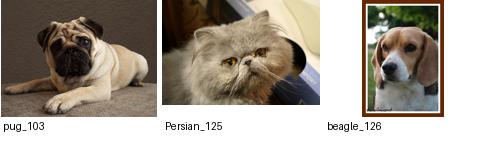

K=2 inertia: 2355.96 / K=3 inertia: 1434.3


In [10]:
# 2-4 실습 코드
m3 = fit_kmeans(X_demo, 3)
track = pd.DataFrame({"image_id": demo_ids, "k2": m.labels_, "k3": m3.labels_})
track["breed"] = meta.loc[track.image_id, "class_name"].values
print("K2 x K3 소속 교차표")
display(pd.crosstab(track.k2, track.k3))
print("K3 x 품종 교차표")
display(pd.crosstab(track.k3, track.breed))
d3 = m3.transform(X_demo)
track["distance3"] = d3[np.arange(len(demo_ids)), m3.labels_]
track = track.sort_values(["k3", "distance3", "image_id"]).reset_index(drop=True)
print("K=3 파일별 소속과 거리")
display(track.round(3))
reps3 = track.groupby("k3").head(1)
print("K=3 대표 사진")
display(reps3.round(3))
display(photo_grid(reps3.image_id.tolist()))
print("K=2 inertia:", round(m.inertia_, 2), "/ K=3 inertia:", round(m3.inertia_, 2))

**나의 답안**

- **근거:**
  - K2×K3 교차표: K=2의 군집 0(8장)이 K=3의 군집 0 **4장** 과 군집 2 **4장** 으로 나뉘었고, K=2의 군집 1(4장)은 K=3의 군집 1 **4장** 으로 그대로 이어졌습니다.
  - K3×품종 교차표: 군집 0 = **pug 4**, 군집 1 = **Persian 4**, 군집 2 = **beagle 4** 로 세 군집 모두 한 품종만 담습니다.
  - K=3 대표: 군집 0 **`pug_103`** (거리 **8.492**), 군집 1 **`Persian_125`** (**9.878**, K=2와 동일), 군집 2 **`beagle_126`** (**8.494**).
  - K=2에서 20.710이던 `pug_116`의 거리는 K=3에서 **14.393**, `beagle_110`은 15.962 → **11.532** 로 줄었고, inertia는 **2355.96 → 1434.3** 으로 감소했습니다.
- **판단:** K를 3으로 늘리자 개 8장이 섞여 있던 기존 군집 0이 퍼그 4장(`pug_100·103·105·116`)과 비글 4장(`beagle_110·111·117·126`)으로 정확히 나뉘었고, 페르시안 묶음은 구성과 대표·거리까지 변하지 않았습니다. 두 모델의 번호는 독립적이라(K=2의 0이 K=3의 0과 같은 뜻이 아님) 같은 파일의 옛 번호와 새 번호를 나란히 놓고 세어야 이 분할을 확인할 수 있습니다. K=2 대표 `beagle_111`은 K=3에서 대표가 아니게 되었고 새 대표는 `beagle_126`입니다. 즉 대표 사진은 K 선택에 따라 바뀌는 상대적인 결과입니다.

## 과제 1 · 사진이 늘어났을 때 군집 수와 검토 순서 결정하기

사진 담당자는 120장으로 폴더를 만든 후 새 사진 40장을 기존 폴더에 넣고 싶습니다. 먼저 품종을 가리고 사진 간 거리만으로 K 후보를 비교하세요. 이어서 **운영팀이 품종별 후보를 살펴볼 폴더 5개를 요청했다**는 조건으로 K=5를 검토합니다. 새 사진의 실제 품종은 배정이 끝난 뒤에만 확인하세요.

### 3-1. 확장 학습 사진 120장으로 K 후보 비교하기

학습 사진만 사용해 K=2, 3, 4, 5, 6을 각각 학습하세요. 같은 표에 거리 제곱합, 평균 실루엣, 가장 작은·큰 군집 장수를 적으세요. K=3에서 첫 사진의 실루엣을 직접 계산하고 어떤 기준에서 K를 택할지 설명하세요.

**풀이 단서**  
실루엣의 a는 자신을 뺀 같은 군집 사진까지의 평균 거리, b는 다른 군집별 평균 거리 중 가장 작은 값입니다. 개별 값은 (b−a)/max(a,b)입니다.

In [11]:
# 3-1 실습 코드
from sklearn.metrics import silhouette_samples

models = {}
rows = []
for k in range(2, 7):
    model = fit_kmeans(X_fit, k)
    models[k] = model
    sizes = np.bincount(model.labels_)
    rows.append({"K": k, "inertia": model.inertia_,
                 "silhouette": silhouette_score(X_fit, model.labels_),
                 "min_size": sizes.min(), "max_size": sizes.max()})
k_table = pd.DataFrame(rows).set_index("K")
display(k_table.round(4))

# K=3에서 첫 학습 사진의 실루엣 직접 계산
labels3 = models[3].labels_
pair = np.sqrt(((X_fit[0] - X_fit) ** 2).sum(axis=1))
own_c = labels3[0]
same = labels3 == own_c
same[0] = False                                # 자기 자신 제외
a = pair[same].mean()
b_each = {int(c): pair[labels3 == c].mean() for c in range(3) if c != own_c}
b = min(b_each.values())
s_manual = (b - a) / max(a, b)
print("첫 학습 사진:", fit_ids[0], "/ 품종:", meta.at[fit_ids[0], "class_name"], "/ 군집:", own_c)
print("a (같은 군집 평균 거리):", round(a, 4))
print("다른 군집별 평균 거리:", {c: round(v, 4) for c, v in b_each.items()}, "-> b =", round(b, 4))
print("직접 계산 실루엣:", round(s_manual, 4))
print("silhouette_samples 값:", round(silhouette_samples(X_fit, labels3)[0], 4))

,inertia,silhouette,min_size,max_size
K,,,,
2,27588.2897,0.2227,48,72
3,23507.2244,0.2246,24,48
4,21260.1600,0.2135,24,48
5,19729.7220,0.1774,16,32
6,19067.7461,0.1621,14,24


첫 학습 사진: beagle_76 / 품종: beagle / 군집: 2
a (같은 군집 평균 거리): 15.4325
다른 군집별 평균 거리: {0: np.float64(23.1995), 1: np.float64(26.0484)} -> b = 23.1995
직접 계산 실루엣: 0.3348
silhouette_samples 값: 0.3348


**나의 답안**

- **근거:**
  - K별 지표 (학습 사진 120장):

    | K | 거리 제곱합 | 평균 실루엣 | 최소 장수 | 최대 장수 |
    |---|---:|---:|---:|---:|
    | 2 | 27588.29 | 0.2227 | 48 | 72 |
    | 3 | 23507.22 | **0.2246** | 24 | 48 |
    | 4 | 21260.16 | 0.2135 | 24 | 48 |
    | 5 | 19729.72 | 0.1774 | 16 | 32 |
    | 6 | 19067.75 | 0.1621 | 14 | 24 |
  - K=3 첫 사진 `beagle_76`(군집 2): a = **15.4325**, 다른 군집별 평균 거리 {0: 23.1995, 1: 26.0484} → b = **23.1995**, 실루엣 (b−a)/max(a,b) = **0.3348** 로 `silhouette_samples` 값 **0.3348** 과 같습니다.
- **판단:** 거리 제곱합은 K가 커질수록 계속 줄어들기 때문에(27588 → 19068) 그 자체로는 K를 고를 수 없고, 감소폭이 K=2→3에서 4081, 5→6에서 662로 작아지는 정도만 참고할 수 있습니다. 거리만 보면 평균 실루엣이 가장 높은 **K=3 (0.2246)** 이 가장 잘 분리된 후보이고, K=2(0.2227)와는 거의 차이가 없으며 K=5 이상은 0.18 이하로 떨어집니다. 다만 실루엣 최댓값이 0.22대로 낮아 어떤 K도 뚜렷하게 분리되었다고 보기는 어렵습니다. 따라서 저는 "거리 지표가 가장 좋은 K"와 "업무에 필요한 폴더 수"를 따로 보고, 품종별 후보 폴더가 필요하다는 운영 조건이 있으면 지표상 최선은 아니어도 K=5를 택하되 최소 군집 16장처럼 작아진 묶음과 실루엣 하락을 감안해 검토 절차를 함께 두겠습니다.

### 3-2. K=5 폴더에 품종 이름을 붙여도 될까?

운영 조건에 따라 K=5 모델을 선택하세요. 학습 사진의 군집×품종 교차표를 만들고, 각 폴더의 최다 품종·해당 장수·폴더 전체 대비 비율을 구하세요. 같은 품종이 둘 이상의 폴더에 나뉜 사례를 한 가지 제시하세요.

**풀이 단서**  
행은 군집입니다. 행 합계가 분모이고 행 최댓값이 분자입니다. 이름표는 학습 사진에서만 결정해 다음 문항에 가져갑니다.

In [12]:
# 3-2 실습 코드
chosen_model = models[5]
fit_df = pd.DataFrame({"image_id": fit_ids, "cluster": chosen_model.labels_})
fit_df["breed"] = meta.loc[fit_df.image_id, "class_name"].values
mix = pd.crosstab(fit_df.cluster, fit_df.breed)
display(mix)
dominant = mix.idxmax(axis=1)
summary = pd.DataFrame({"dominant": dominant,
                        "count": mix.max(axis=1),
                        "total": mix.sum(axis=1)})
summary["ratio"] = (summary["count"] / summary["total"]).round(3)
display(summary)
print("품종별로 사진이 들어간 폴더 수:")
display((mix > 0).sum(axis=0).rename("folders"))
print("어느 폴더에서도 최다 품종이 아닌 품종:", sorted(set(breeds) - set(dominant)))

breed,Birman,Persian,beagle,boxer,pug
cluster,,,,,
0,8,24,0,0,0
1,0,0,0,24,0
2,0,0,24,0,0
3,0,0,0,0,24
4,16,0,0,0,0


,dominant,count,total,ratio
cluster,,,,
0,Persian,24,32,0.75
1,boxer,24,24,1.00
2,beagle,24,24,1.00
3,pug,24,24,1.00
4,Birman,16,16,1.00


품종별로 사진이 들어간 폴더 수:


breed
Birman     2
Persian    1
beagle     1
boxer      1
pug        1
Name: folders, dtype: int64

어느 폴더에서도 최다 품종이 아닌 품종: []


**나의 답안**

- **근거:**
  - K=5 군집×품종 교차표: 군집 0 = **Persian 24 + Birman 8**, 군집 1 = boxer 24, 군집 2 = beagle 24, 군집 3 = pug 24, 군집 4 = **Birman 16**.
  - 폴더별 최다 품종·장수·비율: 0 → Persian **24/32 = 0.75**, 1 → boxer 24/24 = 1.00, 2 → beagle 24/24 = 1.00, 3 → pug 24/24 = 1.00, 4 → Birman 16/16 = 1.00.
  - 둘 이상 폴더에 나뉜 품종: **Birman** 이 군집 0에 **8장**, 군집 4에 **16장** 으로 2개 폴더에 나뉘었습니다.
- **판단:** 개 세 품종 폴더(1·2·3)와 버만 폴더(4)는 학습 사진 기준으로 100% 한 품종이라 품종 이름을 후보 이름표로 붙여도 무리가 없습니다. 그러나 군집 0은 "Persian" 이름이 붙지만 4장 중 1장꼴(8/32)이 버만이어서 이름표만 믿으면 버만 사진을 페르시안 폴더에서 찾게 됩니다. 또 버만 24장 중 3분의 1이 페르시안 폴더로 들어갔으므로 "버만 폴더 = 모든 버만 사진"도 아닙니다. 두 품종 모두 털이 긴 고양이라 특징 공간에서 가까운 것으로 보이며, 이름표는 학습 사진에서만 정한 **후보 이름**으로 쓰고 군집 0은 혼합 폴더라는 주석을 함께 다는 것이 안전합니다.

### 3-3. 기존 중심을 고정해 새 사진 40장 배정하기

추가 fit 없이 새 사진 40장을 K=5의 기존 중심에 배정하세요. 학습 사진에서 정한 최다 품종으로 후보 이름을 붙이고 실제 품종과 대조하세요. 전체 일치율과 품종별 불일치 방향을 구하세요.

**풀이 단서**  
predict는 기존 중심 중 하나를 고릅니다. 새 자료에 fit_predict를 적용하면 중심과 번호가 달라질 수 있습니다. 정답 열은 배정 후 결합하세요.

In [13]:
# 3-3 실습 코드
new_labels = chosen_model.predict(X_new)
new = pd.DataFrame({"image_id": new_ids, "cluster": new_labels})
new["candidate"] = new.cluster.map(dominant)
# 배정이 끝난 뒤에 실제 품종을 결합합니다.
new["breed"] = meta.loc[new.image_id, "class_name"].values
new["match"] = new.candidate == new.breed
print("새 사진 군집별 장수:", np.bincount(new_labels, minlength=5).tolist())
print(f"전체 일치율: {new.match.mean():.3f} ({new.match.sum()}/{len(new)})")
print("실제 품종 x 후보 이름")
display(pd.crosstab(new.breed, new.candidate))
print("품종별 일치율")
display(new.groupby("breed").match.agg(["sum", "count", "mean"]).round(3))
print("불일치 방향 (실제 -> 후보)")
display(new.loc[~new.match].groupby(["breed", "candidate"]).size().rename("count").reset_index())

새 사진 군집별 장수: [10, 8, 8, 8, 6]
전체 일치율: 0.950 (38/40)
실제 품종 x 후보 이름


candidate,Birman,Persian,beagle,boxer,pug
breed,,,,,
Birman,6,2,0,0,0
Persian,0,8,0,0,0
beagle,0,0,8,0,0
boxer,0,0,0,8,0
pug,0,0,0,0,8


품종별 일치율


,sum,count,mean
breed,,,
Birman,6,8,0.75
Persian,8,8,1.00
beagle,8,8,1.00
boxer,8,8,1.00
pug,8,8,1.00


불일치 방향 (실제 -> 후보)


,breed,candidate,count
0,Birman,Persian,2


**나의 답안**

- **근거:**
  - 추가 fit 없이 `predict`로 배정한 새 사진 40장의 군집별 장수는 **[10, 8, 8, 8, 6]** 입니다.
  - 후보 이름과 실제 품종의 **전체 일치율은 0.950 (38/40)** 입니다.
  - 품종별 일치율: Persian·beagle·boxer·pug 각 **8/8 = 1.00**, **Birman 6/8 = 0.75**.
  - 불일치 방향: **Birman → Persian 2장** 이 유일한 불일치이며, 반대 방향(Persian → Birman)이나 개 품종 사이의 혼동은 없습니다.
- **판단:** 학습 사진으로 정한 중심을 그대로 쓰면서도 새 사진 95%가 후보 이름과 맞아, 개 품종과 페르시안 폴더는 새 사진에도 잘 일반화되었습니다. 오류는 모두 3-2에서 이미 확인한 약점, 즉 버만 일부가 "Persian" 폴더(군집 0)로 들어가는 방향에 몰려 있습니다. 그래서 Persian 폴더에 새로 들어간 10장 중 2장이 버만이었고, 이 폴더는 품종 순도가 낮다는 점이 새 사진에서도 반복되었습니다. 새 자료에 `fit_predict`를 쓰지 않고 `predict`만 쓴 덕분에 군집 번호와 이름표가 학습 때와 같은 뜻을 유지했습니다.

### 3-4. 다섯 장만 먼저 열 수 있을 때 검토 목록 작성하기

새 사진을 gap이 작은 순으로 정렬해 우선 검토 5장의 ID·거리·품종과 사진을 출력하세요. 전체 불일치 중 몇 장을 발견하고 몇 장을 놓쳤는지 구하세요. 담당자에게 ① 관찰 사실 ② 가능한 해석 ③ 운영 방법 ④ 추가 검증을 각각 한 문장으로 제안하세요.

**풀이 단서**  
검토 순서는 gap과 파일 ID만으로 정합니다. 순위 결정이 끝난 후 일치 열을 이용해 검토 목록 안과 밖의 불일치를 각각 셉니다.

,image_id,cluster,own,other,gap,candidate,breed,match
0,Birman_89,4,15.179,15.180,0.001,Birman,Birman,True
1,Birman_81,0,13.957,14.573,0.616,Persian,Birman,False
2,Birman_35,4,15.179,16.225,1.046,Birman,Birman,True
3,boxer_85,1,17.911,18.999,1.088,boxer,boxer,True
4,Birman_42,4,13.904,15.246,1.342,Birman,Birman,True


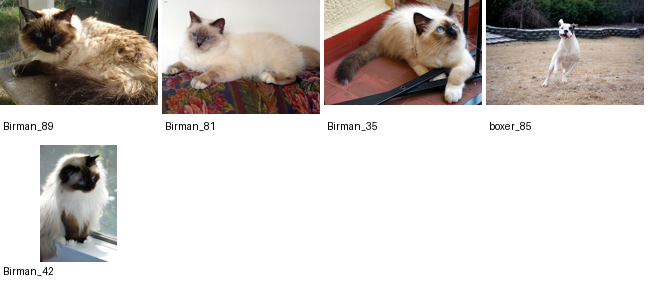

전체 불일치 2장 중 우선 검토 5장에서 발견 1장, 놓친 불일치 1장
놓친 불일치 사진:


,image_id,own,gap,candidate,breed
11,Birman_201,11.644,3.841,Persian,Birman


검토 순위(1부터)별 불일치 위치: [2, 12]


In [14]:
# 3-4 실습 코드
d_new = chosen_model.transform(X_new)
nd = np.sort(d_new, axis=1)
new["own"] = nd[:, 0]
new["other"] = nd[:, 1]
new["gap"] = new["other"] - new["own"]
queue = new.sort_values(["gap", "image_id"]).reset_index(drop=True)
first = queue.head(5)
display(first[["image_id", "cluster", "own", "other", "gap", "candidate", "breed", "match"]].round(3))
display(photo_grid(first.image_id.tolist()))
total_miss = int((~new.match).sum())
found = int((~first.match).sum())
missed = int((~queue.iloc[5:].match).sum())
print(f"전체 불일치 {total_miss}장 중 우선 검토 5장에서 발견 {found}장, 놓친 불일치 {missed}장")
print("놓친 불일치 사진:")
rest = queue.iloc[5:]
display(rest.loc[~rest.match, ["image_id", "own", "gap", "candidate", "breed"]].round(3))
print("검토 순위(1부터)별 불일치 위치:", (queue.index[~queue.match] + 1).tolist())

**나의 답안**

- **근거:**
  - gap 오름차순 우선 검토 5장: `Birman_89` (own 15.179, gap **0.001**, 후보 Birman, 일치), **`Birman_81`** (13.957, gap **0.616**, 후보 Persian, **불일치**), `Birman_35` (15.179, gap 1.046, 일치), `boxer_85` (17.911, gap 1.088, 일치), `Birman_42` (13.904, gap 1.342, 일치).
  - 전체 불일치 **2장** 중 우선 검토 5장에서 **1장(`Birman_81`) 발견**, **1장(`Birman_201`) 놓침**. `Birman_201`은 gap **3.841** 로 검토 순위 **12위** 입니다.
- **판단 (담당자 제안):**
  1. **관찰 사실:** gap이 작은 5장 중 4장이 버만이었고, 이 5장을 열면 불일치 2장 중 1장(`Birman_81`)을 찾지만 `Birman_201`은 12번째라 놓칩니다.
  2. **가능한 해석:** 버만과 페르시안은 털이 긴 고양이라 두 폴더 중심 사이 경계에 버만 사진이 몰리며, `Birman_201`처럼 페르시안 중심에 확실히 가깝게(gap 3.841) 놓인 버만은 gap 기준만으로는 걸러지지 않습니다.
  3. **운영 방법:** 개 폴더 배정은 그대로 믿고, 고양이 두 폴더(특히 "Persian" 폴더)로 들어온 새 사진은 gap이 작은 순서로 열되 검토 범위를 5장보다 넓게(예: 12위까지) 잡아 사람이 확인하겠습니다.
  4. **추가 검증:** 다른 시드로 뽑은 새 사진 묶음에서 gap 순위가 불일치를 몇 위 안에 찾는지 반복 측정하고, 버만·페르시안만 따로 K=2로 다시 나눠 혼동이 줄어드는지 확인하겠습니다.

## 실습 마무리

1. **어떤 문제가 있었나요?** K=2의 대표 한 장으로 군집을 설명할 때 생기는 문제를 실제 파일 ID로 쓰세요.
2. **어떻게 확인했나요?** 거리순 구성 사진과 K 변경 전후의 교차표에서 서로 다른 근거를 하나씩 찾으세요.
3. **무엇을 근거로 운영 방법을 정했나요?** 120장으로 만든 폴더와 새 사진 40장의 결과에서 수치를 하나씩 골라, 담당자가 자동 배정 결과를 어디까지 믿고 무엇을 검토할지 쓰세요.

**나의 답안 (실습 마무리)**

- **1. 어떤 문제가 있었나요?** K=2에서 군집 0의 대표는 **`beagle_111`** (중심 거리 12.083) 한 장이지만, 이 군집에는 비글 4장과 함께 **`pug_100`, `pug_103`, `pug_105`, `pug_116`** 퍼그 4장이 들어 있습니다. 대표 한 장만 보여 주면 이 폴더를 "비글 폴더"로 오해하게 되고, 중심에서 가장 먼 **`pug_116`** (20.710)처럼 대표와 구도·품종이 다른 사진은 전혀 드러나지 않습니다.
- **2. 어떻게 확인했나요?**
  - **거리순 구성 사진:** 군집 0을 거리순으로 펼치자 2·3번째가 이미 `pug_100`(12.837), `pug_103`(12.941)이고 마지막이 `pug_116`(20.710)이어서, 대표 바로 뒤부터 다른 품종이 섞여 있음을 확인했습니다.
  - **K 변경 전후 교차표:** K2×K3 교차표에서 K=2의 군집 0(8장)이 K=3에서 **4장 + 4장** 으로 갈라졌고, K3×품종표에서 그 둘이 각각 **pug 4** 와 **beagle 4** 였습니다. 페르시안 4장은 그대로 유지되었습니다.
- **3. 무엇을 근거로 운영 방법을 정했나요?**
  - **120장 폴더:** K=5에서 개 세 품종과 버만 폴더는 순도 **1.00** 이지만 "Persian" 폴더(군집 0)는 **24/32 = 0.75** 로 버만 8장이 섞였습니다. 또 평균 실루엣은 K=5에서 **0.1774** 로 K=3(0.2246)보다 낮아, 5개 폴더는 운영 요청에 맞춘 선택이지 거리상 최선은 아닙니다.
  - **새 사진 40장:** 전체 일치율 **0.950 (38/40)** 이고 불일치 2장이 모두 **Birman → Persian** 방향이었습니다. gap 상위 5장 검토로는 2장 중 **1장만** 찾았고 `Birman_201`은 12위였습니다.
  - **운영 결정:** 개 품종 폴더(boxer·beagle·pug)의 자동 배정은 학습·새 사진 모두 100% 일치했으므로 그대로 믿고, "Persian"과 "Birman" 고양이 폴더로 들어온 새 사진은 gap이 작은 순으로 사람이 검토하되 5장보다 넓은 범위를 확인하겠습니다. 폴더 이름은 확정 품종이 아니라 학습 사진에서 정한 후보 이름으로 안내하겠습니다.